# 장미 잎 탐색 + 상태 판정 + VLM 검증 (Colab, API 키 파일 방식)

- **1단계 잎 탐색:** 기존 세그멘테이션 모델 `leaf_seg_v8r2.pt`
- **2단계 상태 분류:** 분류 모델 3개 중 선택 (4번 셀의 `CLS_MODEL`, 클래스는 모두 black_spot, downy_mildew, healthy, insects_infected)
- **3단계 VLM 검증 (선택):** 이상·의심 잎과 건강 잎 일부를 VLM(Claude 또는 Qwen2.5-VL)에게 다시 보여 주고 판정을 비교

**실행 순서**
1. 메뉴에서 **런타임 > 런타임 유형 변경 > T4 GPU**를 선택합니다.
2. `rose_leaf_colab_package.zip`을 Google Drive의 `내 드라이브/rose_leaf_colab(VLM적용+API방식변경)` 폴더에 올려 둡니다. 다른 폴더에 두려면 2번 셀의 `Path("/content/drive/MyDrive/rose_leaf_colab(VLM적용+API방식변경)")` 경로를 바꿉니다. zip을 찾지 못하면 2번 셀에서 직접 업로드하라고 안내합니다.
3. Claude로 VLM 검증(6번 단계)을 하려면 API 키를 적은 파일 `ANTHROPIC_API_KEY`(또는 `ANTHROPIC_API_KEY.txt`)를 Drive의 `내 드라이브/rose_leaf_colab(VLM적용+API방식변경)` 폴더에 올려 둡니다. 파일 만드는 법과 폴더 바꾸는 법은 6번 단계의 **API 키 파일 넣는 방법**에 있습니다.
4. 위에서부터 셀을 차례대로 실행합니다.

## 1. GPU 확인

In [1]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (CPU로 실행되어 느립니다. 런타임 유형을 T4 GPU로 바꾸세요)")

GPU: Tesla T4


## 2. 패키지 가져오기 및 설치

In [3]:
import os, shutil, zipfile
from pathlib import Path
from google.colab import drive, files

USE_DRIVE = True  # Drive를 쓰지 않으려면 False
ZIP_NAME = "rose_leaf_colab_package.zip"
WORK = Path("/content/rose_leaf")

zip_path = None
if USE_DRIVE:
    drive.mount("/content/drive")
    p = Path("/content/drive/MyDrive/rose_leaf_colab(VLM적용+API방식변경)") / ZIP_NAME
    if p.exists():
        zip_path = p
    else:
        print("Drive에서 찾지 못했습니다:", p)
if zip_path is None:
    print(ZIP_NAME, "파일을 선택해 업로드하세요")
    zip_path = Path("/content") / next(iter(files.upload()))

shutil.rmtree(WORK, ignore_errors=True)
zipfile.ZipFile(zip_path).extractall(WORK)
print("압축 해제 완료:", sorted(x.name for x in WORK.iterdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
압축 해제 완료: ['config.json', 'leafdx', 'models', 'requirements.txt', 'run.py', 'samples', 'verify.py']


In [4]:
!pip install -q -r /content/rose_leaf/requirements.txt

## 3. 사진 올리기

사진(jpg, png, bmp, webp)을 여러 장 선택할 수 있습니다. 아무것도 선택하지 않고 취소하면 포함된 샘플 사진으로 실행합니다.

In [5]:
PHOTOS = Path("/content/photos")
shutil.rmtree(PHOTOS, ignore_errors=True)
PHOTOS.mkdir()

try:
    uploaded = files.upload()
except Exception:
    uploaded = {}
for name in uploaded:
    shutil.move(f"/content/{name}", PHOTOS / name)
if not uploaded:
    shutil.copy(WORK / "samples" / "fix_eafda190.jpg", PHOTOS)
    print("샘플 사진으로 실행합니다")
print(sorted(x.name for x in PHOTOS.iterdir()))

Saving CL (1).jpg to CL (1).jpg
['CL (1).jpg']


## 4. 실행

분류 모델을 `CLS_MODEL`에서 고릅니다. 잎 탐색(1단계) 모델은 같습니다.

| CLS_MODEL | 모델 | val 정확도 |
|---|---|---|
| `leaf_cls_yolov8m.pt` | YOLOv8m-cls (첫 번째 모델) | 0.957 |
| `leaf_cls_yolov8m_du.pt` | YOLOv8m-cls (du) | 0.950 |
| `leaf_cls_yolo26m_du.pt` | YOLO26m-cls (du) | 0.948 |

val 정확도는 각 모델 파일에 저장된 학습 기록 값입니다.

In [6]:
CLS_MODEL = "leaf_cls_yolov8m.pt"  # "leaf_cls_yolov8m.pt" | "leaf_cls_yolov8m_du.pt" | "leaf_cls_yolo26m_du.pt"

RESULTS = Path("/content/results")
shutil.rmtree(RESULTS, ignore_errors=True)
!cd /content/rose_leaf && python run.py /content/photos --out /content/results --cls {CLS_MODEL}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
classifier leaf_cls_yolov8m.pt
CL (1).jpg 523 {'HOLD_SHAPE': 29, 'FRESH': 489, 'ANOMALY:insects_infected': 2, 'ANOMALY:black_spot': 1, 'ANOMALY:downy_mildew': 2} {'stage1_s': 9.57, 'stage2_s': 3.38}


## 5. 결과 보기

| 상태 | 의미 |
|---|---|
| FRESH | 건강 |
| ANOMALY:black_spot / downy_mildew / insects_infected | 이상 (클래스 표시) |
| UNKNOWN | 이상 의심, 관찰 대상 |
| HOLD_SHAPE | 잎이 합쳐졌거나 사진 가장자리에 잘림, 판정 안 함 |

,photo,cls_model,leaves,L,ANOMALY:black_spot,ANOMALY:downy_mildew,ANOMALY:insects_infected,FRESH,HOLD_SHAPE,stage1_s,stage2_s
0,CL (1).jpg,leaf_cls_yolov8m.pt,523,95.4,1,2,2,489,29,9.57,3.38


CL (1)_vis.jpg


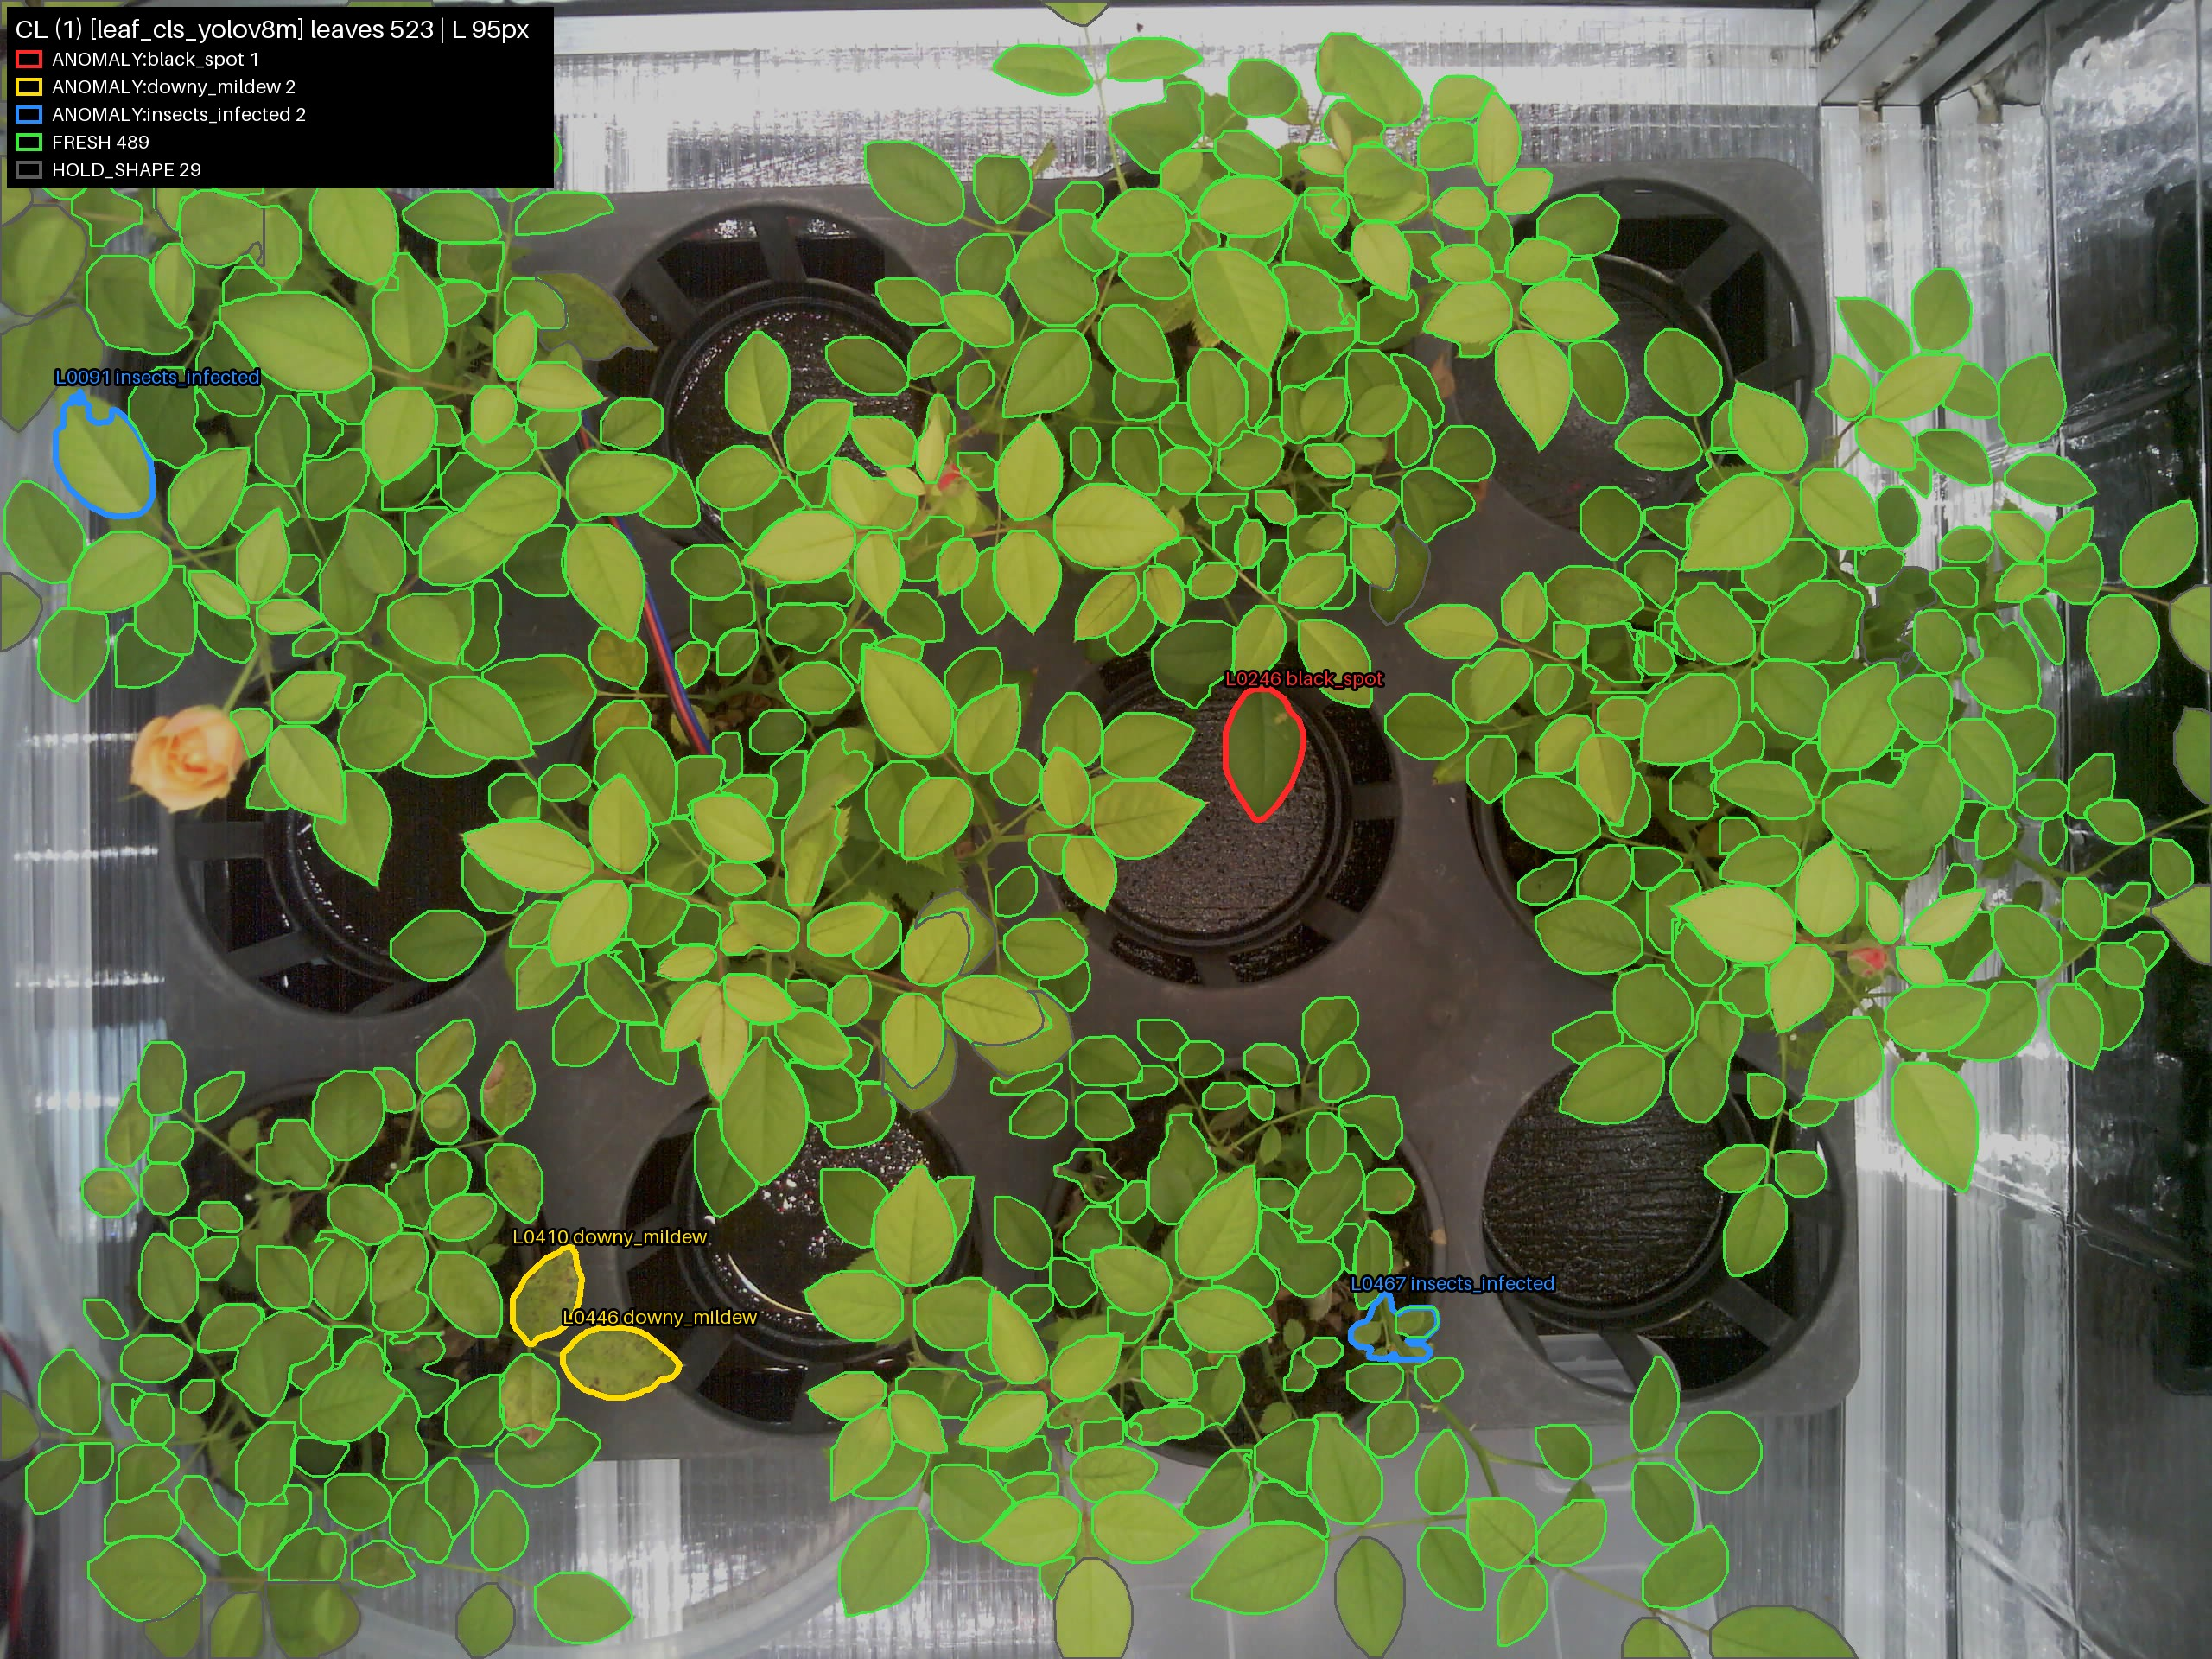

In [7]:
import json
import pandas as pd
from IPython.display import Image, display

display(pd.read_csv(RESULTS / "summary.csv"))
for f in sorted(RESULTS.glob("*_vis.jpg")):
    print(f.name)
    display(Image(filename=str(f), width=1000))

이상 또는 의심으로 판정된 잎 목록입니다.

In [8]:
rows = []
for f in sorted(RESULTS.glob("*.json")):
    if f.stem.endswith("_vlm"):
        continue
    d = json.loads(f.read_text())
    for l in d["leaves"]:
        if l["state"] in ("ANOMALY", "UNKNOWN"):
            rows.append(dict(photo=d["photo"], id=l["id"], state=l["state"], cls=l["anomaly_class"], box=l["box"], **l["probs"]))
display(pd.DataFrame(rows) if rows else "이상 또는 의심 잎 없음")

,photo,id,state,cls,box,black_spot,downy_mildew,healthy,insects_infected
0,CL (1).jpg,L0091,ANOMALY,insects_infected,"[64, 448, 177, 598]",0.0002,0.0009,0.1397,0.8592
1,CL (1).jpg,L0246,ANOMALY,black_spot,"[1418, 797, 1509, 950]",0.5932,0.0163,0.3903,0.0002
2,CL (1).jpg,L0410,ANOMALY,downy_mildew,"[593, 1443, 674, 1556]",0.1271,0.8497,0.0228,0.0004
3,CL (1).jpg,L0446,ANOMALY,downy_mildew,"[651, 1536, 787, 1618]",0.1497,0.8486,0.0011,0.0006
4,CL (1).jpg,L0467,ANOMALY,insects_infected,"[1563, 1497, 1664, 1574]",0.0000,0.0000,0.3407,0.6593


## 6. VLM으로 검증 (선택)

분류 모델의 결과를 VLM에게 한 번 더 확인받습니다. 각 잎마다 **확대 사진**과 **잎 윤곽을 표시한 주변 사진** 두 장을 보내고,
분류 모델의 답은 알려 주지 않은 채(선입견 없이) 6가지 중 하나로 판정하게 한 뒤 결과를 비교합니다.

- 검증 대상: 이상(ANOMALY)·의심(UNKNOWN) 잎 전부 + 건강(FRESH) 잎 중 무작위 `FRESH_SAMPLE`장 (놓친 이상이 있는지 확인용)
- **Claude** (`VLM_BACKEND = "claude"`): Anthropic API 키가 필요하고 사용량만큼 요금이 나갑니다.
  키는 파일에서 읽습니다. 파일 만드는 법과 넣는 곳은 바로 아래 **API 키 파일 넣는 방법**에 있습니다.
- **Qwen2.5-VL-3B** (`VLM_BACKEND = "qwen"`): 무료 오픈 모델, T4 GPU에서 실행 (처음에 약 7GB 내려받음). Claude보다 판단력이 약합니다.
- `"auto"`: 키가 있으면 Claude, 없으면 Qwen

| 비교 결과 (verdict) | 의미 |
|---|---|
| AGREE | 분류 모델과 VLM 판정 일치 |
| FALSE_ALARM | 분류 모델은 이상, VLM은 건강 → 오경보 가능성 |
| MISSED | 분류 모델은 건강, VLM은 이상 → 놓친 이상 가능성 |
| OTHER_CLASS | 둘 다 이상이지만 종류가 다름 |
| VLM_HEALTHY / VLM_ANOMALY | 분류 모델이 의심(UNKNOWN)으로 남긴 잎에 대한 VLM 판정 |
| NOT_A_LEAF | 실제 잎이 아님 (거울 반사, 줄기, 여러 잎이 합쳐짐 등) |
| UNCLEAR | VLM도 판단 불가 |

### API 키 파일 넣는 방법 (Claude를 쓸 때만)

이 노트북은 키를 **이름이 `ANTHROPIC_API_KEY`인 텍스트 파일**에서 읽습니다. 코드에 키를 직접 적지 않습니다.
(Colab 보안 비밀로 넣으려면 `rose_leaf_colab.ipynb`를 쓰세요.)

**1. API 키 발급**
1. Anthropic Console(console.anthropic.com)에 로그인합니다.
2. **API Keys** 메뉴에서 **Create Key**를 눌러 키를 만듭니다.
3. 만들어진 키(`sk-ant-`로 시작)를 복사합니다. 키는 만들 때 한 번만 보이므로 바로 복사해 둡니다.
4. 호출 요금은 Console의 **Billing**에 충전된 크레딧에서 나갑니다. 크레딧이 없으면 호출이 실패합니다.

**2. 키 파일 만들기 (Windows 메모장)**
1. 메모장을 열고 키 한 줄만 붙여 넣습니다. 다른 글자나 빈칸은 넣지 않습니다.
2. **파일 > 다른 이름으로 저장**에서 파일 이름을 `ANTHROPIC_API_KEY`로 입력합니다.
3. **파일 형식**을 **모든 파일**로, **인코딩**을 **UTF-8**로 두고 저장합니다.
   텍스트 문서로 저장해 `ANTHROPIC_API_KEY.txt`가 되어도 읽습니다.
- `ANTHROPIC_API_KEY=sk-ant-...` 형식, 앞뒤 공백·줄바꿈, 따옴표, `#`으로 시작하는 주석 줄도 괜찮습니다.

**3. 키 파일 올리기**

아래 키 읽기 셀은 다음 순서로 파일을 찾습니다.
1. Drive의 `내 드라이브/rose_leaf_colab(VLM적용+API방식변경)` 폴더 (키 읽기 셀의 `KEY_DIRS` 첫 줄)
2. `/content` (Colab 왼쪽 파일 패널로 올린 경우. 런타임이 끊기면 지워집니다)
3. 둘 다 없으면 업로드 창이 뜹니다. Claude를 쓰지 않으면 취소하세요.

다른 Drive 폴더에 두려면 키 읽기 셀의 `KEY_DIRS` 첫 줄 경로를 그 폴더로 바꿉니다.
예: `내 드라이브` 바로 아래라면 `Path("/content/drive/MyDrive")`

**4. 확인**
1. 키 읽기 셀을 실행합니다.
2. `API 키를 읽었습니다: <파일 경로> (sk-ant-...XXXX, 키 글자 수)` 처럼 나오면 성공입니다. 키는 앞 7자와 끝 4자만 표시합니다.
   이어서 `--dry-run`과 검증 셀 결과에 `backend claude`가 나옵니다.
3. 다른 메시지가 나오면 아래를 확인합니다.
   - `API 키 파일을 찾지 못했습니다`: 파일 이름과 올린 폴더, `KEY_DIRS` 첫 줄 경로
   - `키 파일이 비어 있습니다`: 파일에 키를 붙여 넣고 저장했는지
   - `주의: ... sk-ant- 로 시작합니다`: 키를 잘못 복사했는지
   - `API 키 없음`: `VLM_BACKEND = "auto"`이면 Qwen으로 실행됩니다

**알아 둘 점**
- 키 파일은 결과 zip에 들어가지 않습니다.
- 키 파일을 남과 공유하는 Drive 폴더나 다른 사람에게 보내는 압축 파일에 넣지 마세요.
- 키를 코드 셀에 직접 붙여 넣지 마세요. 노트북을 저장하거나 공유할 때 키가 함께 남습니다.
- 키가 유출됐다고 생각되면 Anthropic Console에서 그 키를 바로 삭제하고 새로 만듭니다.

In [9]:
# API 키 파일 읽기: 이름이 ANTHROPIC_API_KEY 인 텍스트 파일, 내용은 키 한 줄
KEY_NAMES = ["ANTHROPIC_API_KEY", "ANTHROPIC_API_KEY.txt"]  # 메모장으로 만들면 .txt가 붙는 경우가 많음
KEY_DIRS = [Path("/content/drive/MyDrive/rose_leaf_colab(VLM적용+API방식변경)"), Path("/content"), WORK]


def read_key(path):
    """First non-empty, non-comment line; accepts NAME=value and quotes."""
    for line in path.read_text(encoding="utf-8-sig").splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if "=" in line:
            line = line.split("=", 1)[1].strip()
        return line.strip("'\"")
    return ""


key_file = next((d / n for d in KEY_DIRS for n in KEY_NAMES if (d / n).is_file()), None)
if key_file is None:
    print("API 키 파일을 찾지 못했습니다:", ", ".join(str(d / KEY_NAMES[0]) for d in KEY_DIRS[:2]))
    print("ANTHROPIC_API_KEY 파일을 선택해 업로드하세요 (Claude를 쓰지 않으면 취소)")
    try:
        up = files.upload()
    except Exception:
        up = {}
    if up:
        key_file = Path("/content") / next(iter(up))

os.environ.pop("ANTHROPIC_API_KEY", None)
if key_file is not None:
    key = read_key(key_file)
    if key:
        os.environ["ANTHROPIC_API_KEY"] = key
        print(f"API 키를 읽었습니다: {key_file} ({key[:7]}...{key[-4:]}, {len(key)}자)")
        if not key.startswith("sk-ant-"):
            print("주의: Anthropic API 키는 보통 sk-ant- 로 시작합니다. 파일 내용을 확인하세요")
    else:
        print("키 파일이 비어 있습니다:", key_file)
if not os.environ.get("ANTHROPIC_API_KEY"):
    print("API 키 없음: VLM_BACKEND가 auto면 Qwen으로 실행합니다")

API 키를 읽었습니다: /content/drive/MyDrive/rose_leaf_colab(VLM적용+API방식변경)/ANTHROPIC_API_KEY.txt (sk-ant-...DwAA, 106자)


In [10]:
VLM_BACKEND = "auto"               # "auto" | "claude" | "qwen"
CLAUDE_MODEL = "claude-opus-5-5"
QWEN_MODEL = "Qwen/Qwen2.5-VL-3B-Instruct"
FRESH_SAMPLE = 5                   # 사진마다 검증할 건강 잎 수
MAX_PER_PHOTO = 40                 # 사진마다 검증할 최대 잎 수 (비용 상한)

VLM_MODEL = CLAUDE_MODEL if VLM_BACKEND == "claude" or (VLM_BACKEND == "auto" and os.environ.get("ANTHROPIC_API_KEY")) else QWEN_MODEL
!cd /content/rose_leaf && python verify.py --photos /content/photos --results /content/results --backend {VLM_BACKEND} --model {VLM_MODEL} --fresh {FRESH_SAMPLE} --max {MAX_PER_PHOTO} --dry-run

CL (1).jpg: 10 leaves to review
total 10 leaves


위에 나온 검증할 잎 수를 확인한 뒤 실행합니다. Claude는 잎 하나에 요청 한 번이 나갑니다.

In [11]:
!cd /content/rose_leaf && python verify.py --photos /content/photos --results /content/results --backend {VLM_BACKEND} --model {VLM_MODEL} --fresh {FRESH_SAMPLE} --max {MAX_PER_PHOTO}

CL (1).jpg: 10 leaves to review
total 10 leaves
backend claude claude-opus-5-5
CL (1).jpg {'FALSE_ALARM': 1, 'OTHER_CLASS': 2, 'NOT_A_LEAF': 2, 'UNCLEAR': 1, 'AGREE': 4}
verdicts {'FALSE_ALARM': 1, 'OTHER_CLASS': 2, 'NOT_A_LEAF': 2, 'UNCLEAR': 1, 'AGREE': 4}
tokens in/out [20684, 1266] approx $0.108


verdict,AGREE,FALSE_ALARM,NOT_A_LEAF,OTHER_CLASS,UNCLEAR
photo,,,,,
CL (1).jpg,4,1,2,2,1


,photo,cls_model,id,model,model_p,vlm_label,confidence,verdict,symptoms,reason,error
0,CL (1).jpg,leaf_cls_yolov8m.pt,L0091,insects_infected,0.8592,healthy,medium,FALSE_ALARM,잎은 전체적으로 균일한 연녹색이며 반점이나 구멍이 보이지 않습니다.,"윗부분의 움푹한 윤곽은 다른 잎에 가려진 부분으로 보이며, 실제로 먹힌 흔적이나 질...",NaN
1,CL (1).jpg,leaf_cls_yolov8m.pt,L0410,downy_mildew,0.8497,black_spot,medium,OTHER_CLASS,잎 전체가 황변되어 있고 여러 개의 작은 갈색~흑색 반점이 흩어져 있습니다.,둥근 어두운 반점과 주변 황변이 흑점병의 전형적인 증상과 일치합니다.,NaN
2,CL (1).jpg,leaf_cls_yolov8m.pt,L0446,downy_mildew,0.8486,black_spot,medium,OTHER_CLASS,황록색으로 변한 잎에 작고 둥근 갈색~흑갈색 반점이 여러 개 흩어져 있습니다.,잎 전체 황화와 함께 둥근 암갈색 반점이 보여 흑점병의 전형적인 증상과 일치합니다.,NaN
3,CL (1).jpg,leaf_cls_yolov8m.pt,L0467,insects_infected,0.6593,not_a_leaf,high,NOT_A_LEAF,윤곽 안에 줄기와 여러 장의 작은 잎이 함께 포함되어 있습니다.,윤곽이 한 장의 잎이 아니라 줄기와 여러 잎을 하나로 묶고 있습니다.,NaN
4,CL (1).jpg,leaf_cls_yolov8m.pt,L0246,black_spot,0.5932,unclear,low,UNCLEAR,"잎 오른쪽 위 가장자리 근처에 작은 노란색-주황색 반점이 하나 있고, 가장자리가 약...","반점이 작고 하나뿐이며 둥근 흑갈색 반점이나 잎맥에 경계 지어진 각진 반점, 갉아먹...",NaN
5,CL (1).jpg,leaf_cls_yolov8m.pt,L0457,healthy,1.0000,healthy,high,AGREE,잎 전체가 균일한 연두색이며 반점이나 구멍이 보이지 않습니다.,질병이나 해충 피해 증상이 없는 정상적인 잎으로 판단됩니다.,NaN
6,CL (1).jpg,leaf_cls_yolov8m.pt,L0213,healthy,0.9999,healthy,medium,AGREE,"균일한 연녹색 잎으로 반점, 구멍, 변색이 보이지 않습니다.",윤곽 안의 잎은 실제 잎으로 보이며 질병이나 해충 피해 징후 없이 고르게 녹색입니다.,NaN
7,CL (1).jpg,leaf_cls_yolov8m.pt,L0412,healthy,1.0000,healthy,high,AGREE,잎 전체가 균일한 연두색이며 반점이나 구멍 등의 이상이 보이지 않습니다.,"연한 황록색은 정상적인 새잎의 색으로, 질병이나 해충 피해의 징후가 없습니다.",NaN
8,CL (1).jpg,leaf_cls_yolov8m.pt,L0482,healthy,0.9994,not_a_leaf,medium,NOT_A_LEAF,윤곽선 안에 여러 장의 잎이 겹쳐 하나로 묶여 있는 것으로 보입니다.,한 장의 잎이 아니라 겹친 잎 여러 장을 하나의 윤곽으로 감싼 것으로 판단됩니다.,NaN
9,CL (1).jpg,leaf_cls_yolov8m.pt,L0232,healthy,1.0000,healthy,medium,AGREE,잎 전체가 균일한 연두색이며 반점이나 구멍이 보이지 않습니다.,질병이나 해충 증상이 관찰되지 않아 건강한 잎으로 판단됩니다.,NaN


CL (1)_vlm.jpg


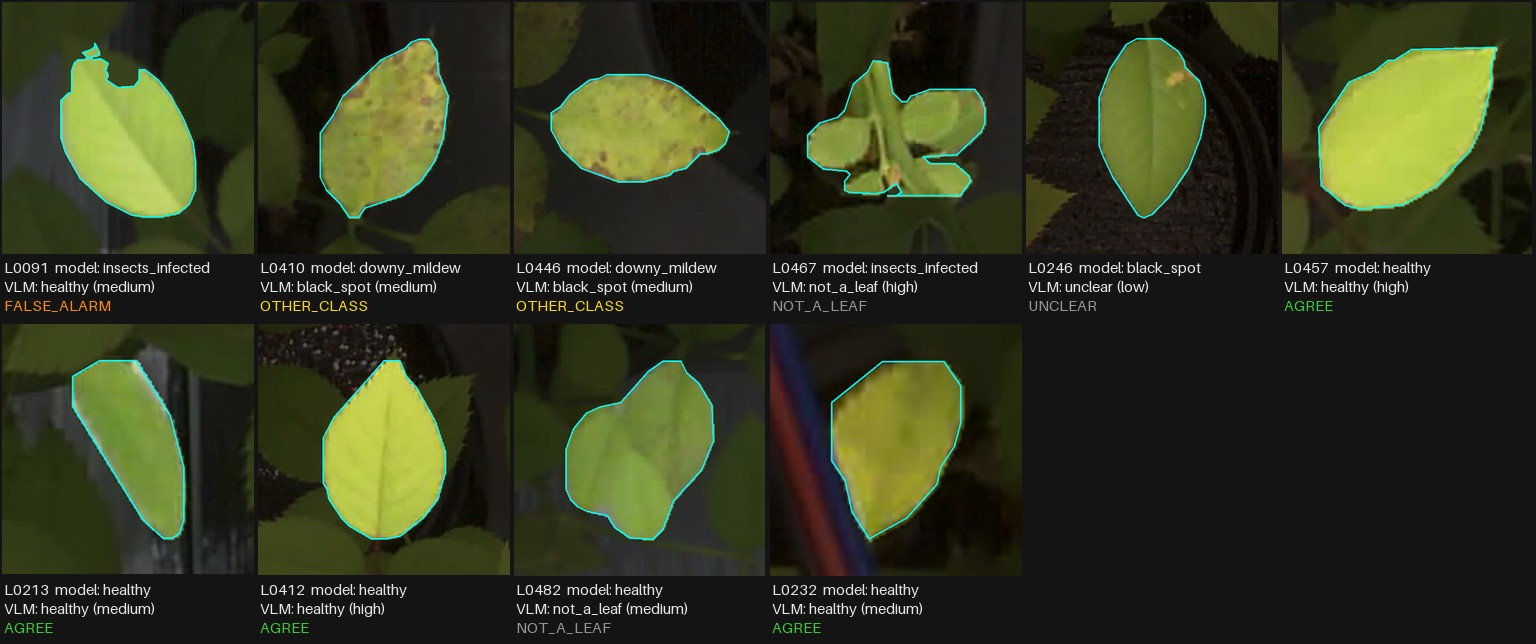

In [12]:
review = pd.read_csv(RESULTS / "vlm_review.csv")
display(review.groupby(["photo", "verdict"]).size().unstack(fill_value=0))
display(review[["photo", "cls_model", "id", "model", "model_p", "vlm_label", "confidence", "verdict", "symptoms", "reason", "error"]])
for f in sorted(RESULTS.glob("*_vlm.jpg")):
    print(f.name)
    display(Image(filename=str(f), width=1000))

## 7. 결과 내려받기

In [13]:
shutil.make_archive("/content/results", "zip", RESULTS)
files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>